# Background Remover - Eliminar Isles Mal Etiquetadas

Este notebook contiene técnicas para:
1. Detectar el fondo de imágenes histológicas (blanco/gris)
2. Comparar con anotaciones GeoJSON para encontrar regiones mal etiquetadas
3. Aplicar connected components para eliminar "islas" pequeñas

In [1]:
import cv2
import numpy as np
import geojson
from shapely.geometry import shape
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
# Rutas
DATA = Path("../../data")
DATA_DIR = Path("../../data/raw")
WSI_DIR = DATA_DIR / "wsi_images"
ANNOT_DIR = DATA_DIR / "annotations_resized"
OUTPUT_DIR = DATA / "processed" / "back_remover"
OUTPUT_DIR.mkdir(exist_ok=True)

# Ejemplo: slide_001
slide_id = "slide_001"

## 1. Cargar Imagen y Anotaciones

In [3]:
# Cargar imagen WSI
img_path = WSI_DIR / f"{slide_id}.tif"
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(f"Imagen cargada: {img.shape}")

# Cargar anotaciones GeoJSON
annot_path = ANNOT_DIR / f"{slide_id}.geojson"
with open(annot_path, 'r') as f:
    annotations = geojson.load(f)

print(f"Número de features: {len(annotations['features'])}")

Imagen cargada: (6240, 8686, 3)
Número de features: 6


In [ ]:
import tifffile

#Visualize image rgb
plt.figure(figsize=(10, 10))
plt.imshow(img_rgb)
plt.axis('off')
plt.title(f"Imagen WSI - {slide_id}")
plt.show()

## 2. Técnica 1: Background Removal (HSV Thresholding)

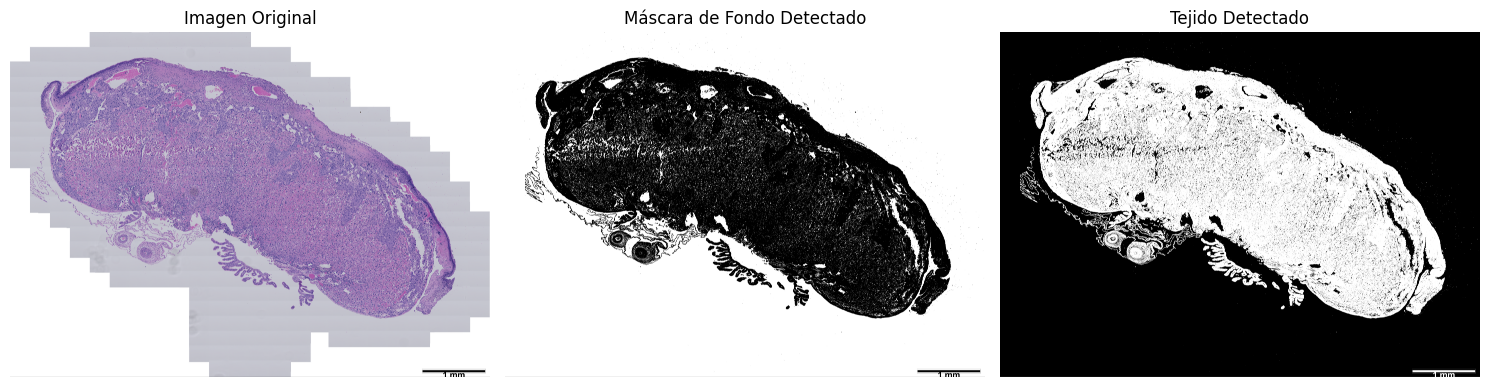

Porcentaje de fondo: 65.24%


In [8]:
def detect_background_hsv(image, sat_threshold=30, value_threshold=200):
    """
    Detecta el fondo blanco/gris de imágenes histológicas usando HSV.
    
    Fondo blanco/gris: Alta luminosidad (V), baja saturación (S)
    """
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    
    # Máscara para fondo blanco/gris (baja saturación, alto valor)
    lower_white = np.array([0, 0, value_threshold])
    upper_white = np.array([180, sat_threshold, 255])
    
    mask = cv2.inRange(hsv, lower_white, upper_white)
    
    # Invertir: 1 = fondo, 0 = tejido
    return mask

# Detectar fondo
numb_sat = 30
value_threshold = 180
#for i in range(5):
background_mask = detect_background_hsv(img, sat_threshold=numb_sat, value_threshold=value_threshold)

# Visualizar
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_rgb)
axes[0].set_title('Imagen Original')
axes[0].axis('off')

axes[1].imshow(background_mask, cmap='gray')
axes[1].set_title('Máscara de Fondo Detectado')
axes[1].axis('off')

# Invertir para ver tejido detectado
tissue_mask = cv2.bitwise_not(background_mask)
axes[2].imshow(tissue_mask, cmap='gray')
axes[2].set_title('Tejido Detectado')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"Porcentaje de fondo: {np.sum(background_mask > 0) / background_mask.size * 100:.2f}%")

## 3. Rasterizar Anotaciones GeoJSON a Máscara

Máscara de anotaciones creada: (6240, 8686)
Porcentaje anotado: 32.72%


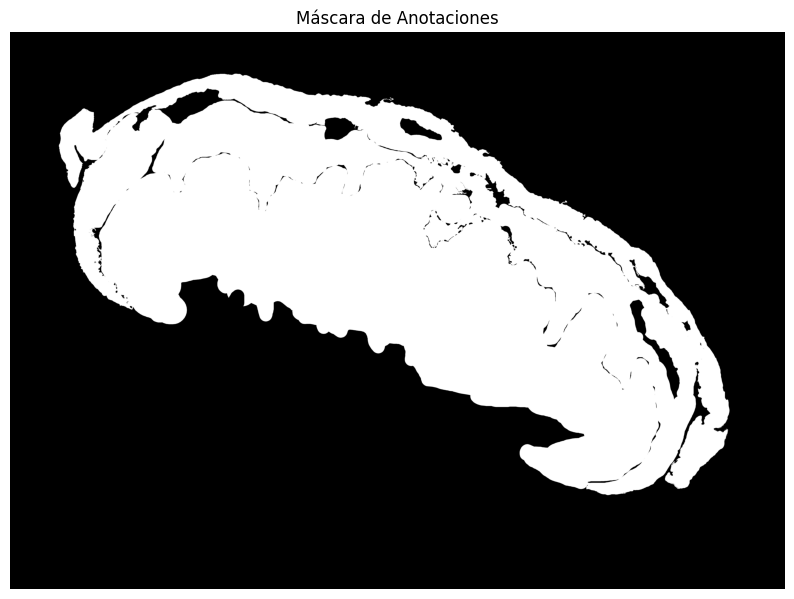

In [9]:
# Convertir datos vectoriales (es decir, polígonos) a una máscara binaria.

def rasterize_annotations(annotations, img_shape):
    """
    Convierte anotaciones GeoJSON a máscara binaria.
    Soporta Polygon y MultiPolygon con holes.
    """
    h, w = img_shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    
    for feature in annotations['features']:
        geom = shape(feature['geometry'])
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            # Exterior
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(mask, [ext_coords], 255)
            
            # Interiors (holes)
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(mask, [int_coords], 0)
    
    return mask

# Crear máscara de anotaciones
annot_mask = rasterize_annotations(annotations, img.shape)

print(f"Máscara de anotaciones creada: {annot_mask.shape}")
print(f"Porcentaje anotado: {np.sum(annot_mask > 0) / annot_mask.size * 100:.2f}%")

plt.figure(figsize=(10, 10))
plt.imshow(annot_mask, cmap='gray')
plt.title('Máscara de Anotaciones')
plt.axis('off')
plt.show()

## 4. Detectar Isles Mal Etiquetadas

bitwise_and() aplica AND -> BIT a BIT 

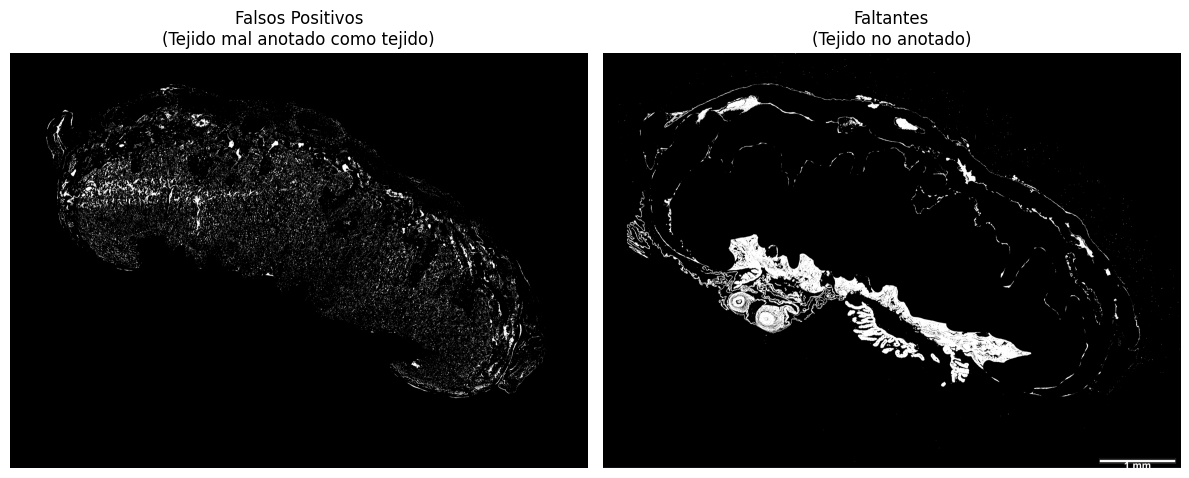

Falsos positivos (m² mal etiquetado): 2.84%
Faltantes (tejido sin anotar): 4.88%


In [10]:
# Encontrar regiones en la máscara de anotaciones que están en área de fondo
# Esto son "islas" mal etiquetadas (tejido donde debería haber fondo)

# Región anotada que está en fondo = MAL ETIQUETADA
false_positives = cv2.bitwise_and(annot_mask, background_mask)
'''
Si está en mascara anotación(es decir 1 en ese pixel) y aparece en la máscara de fondo generada (o viceversa) 
MAL ANOTADA.
'''

# Región no anotada que es tejido = NO ANOTADA (potencialmente faltante)
false_negatives = cv2.bitwise_and(tissue_mask, cv2.bitwise_not(annot_mask))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(false_positives, cmap='gray')
axes[0].set_title('Falsos Positivos\n(Tejido mal anotado como tejido)')
axes[0].axis('off')

axes[1].imshow(false_negatives, cmap='gray')
axes[1].set_title('Faltantes\n(Tejido no anotado)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"Falsos positivos (m² mal etiquetado): {np.sum(false_positives > 0) / false_positives.size * 100:.2f}%")
print(f"Faltantes (tejido sin anotar): {np.sum(false_negatives > 0) / false_negatives.size * 100:.2f}%")

## 5. Técnica 3: Connected Components para Eliminar Isles por Tamaño

### Esto lo usaría como post-procesamiento de la inferencia del modelo

Total de componentes encontrados: 56534
Componentes eliminados (< 1000 px): 56397
Componentes mantenidos (>= 1000 px): 137


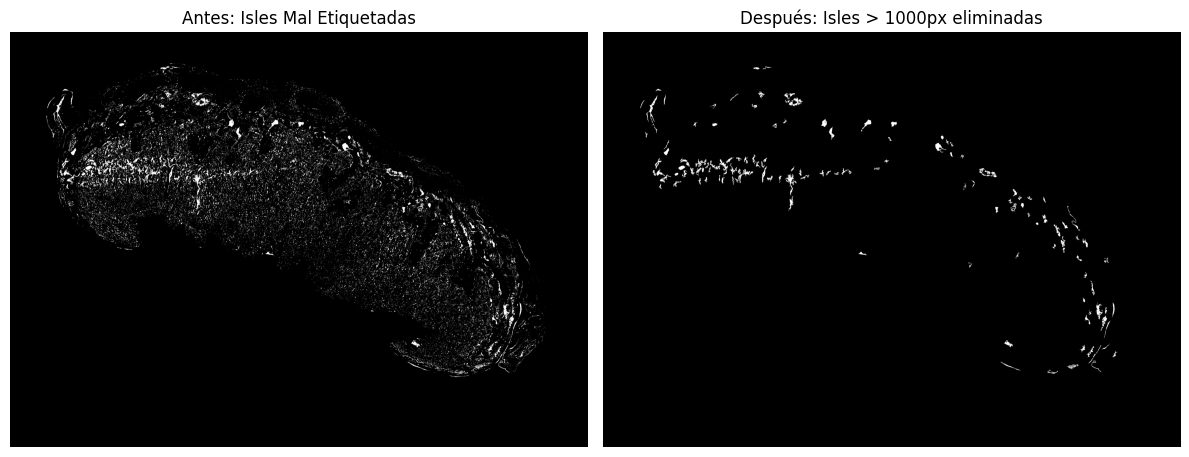

In [11]:
def remove_small_islands(mask, min_area=1000, show_stats=False):
    """
    Elimina componentes conectados menores a min_area píxeles.
    
    Args:
        mask: Máscara binaria (255 = objeto, 0 = fondo)
        min_area: Área mínima en píxeles para mantener el componente
        show_stats: Si True, muestra estadísticas de los componentes
    
    Returns:
        clean_mask: Máscara con islas pequeñas eliminadas
    """
    # Obtener componentes conectados
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)
    
    # Crear máscara limpia
    clean_mask = np.zeros_like(mask)
    
    # Áreas de cada componente
    areas = stats[:, cv2.CC_STAT_AREA]
    
    if show_stats:
        print(f"Total de componentes encontrados: {num_labels - 1}")  # -1 porque el fondo es 0
        print(f"Componentes eliminados (< {min_area} px): {np.sum(areas[1:] < min_area)}")
        print(f"Componentes mantenidos (>= {min_area} px): {np.sum(areas[1:] >= min_area)}")
    
    # Mantener solo componentes con área >= min_area
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            clean_mask[labels == i] = 255
    
    return clean_mask

# Aplicar a la máscara de falsos positivos (islas mal etiquetadas)
min_island_area = 1000  # Ajustar según necesidad
cleaned_fp = remove_small_islands(false_positives, min_area=min_island_area, show_stats=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(false_positives, cmap='gray')
axes[0].set_title('Antes: Isles Mal Etiquetadas')
axes[0].axis('off')

axes[1].imshow(cleaned_fp, cmap='gray')
axes[1].set_title(f'Después: Isles > {min_island_area}px eliminadas')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 6. Función Completa: Pipeline de Limpieza

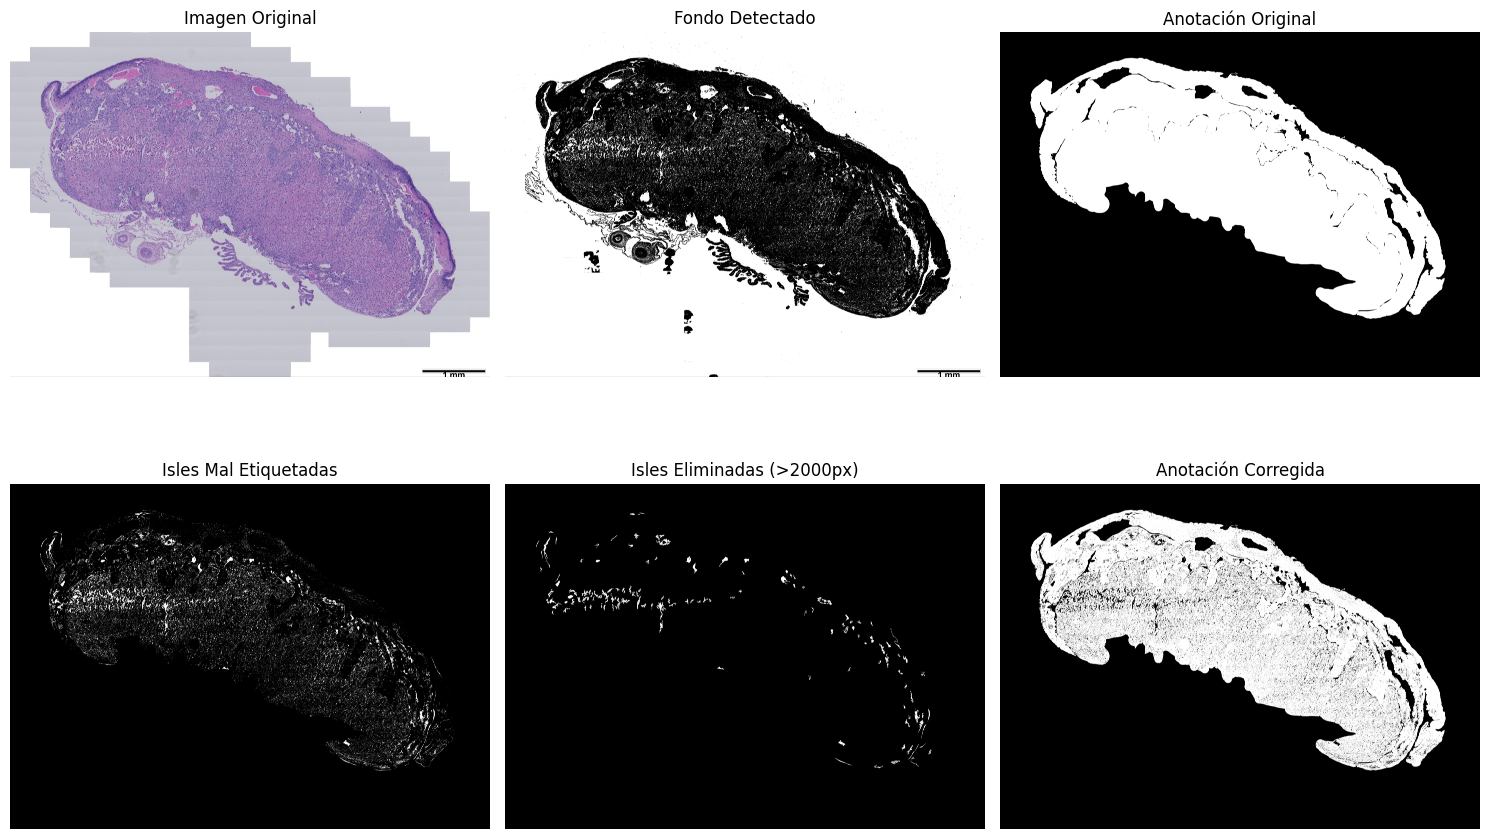

In [ ]:
def clean_annotations(img_path, annot_path, 
                       sat_threshold=30, 
                       value_threshold=200,
                       min_island_area=5000,
                       visualize=True):
    """
    Pipeline completo para limpiar anotaciones de "islas" mal etiquetadas.
    """
    # Cargar imagen
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Cargar anotaciones
    with open(annot_path, 'r') as f:
        annotations = geojson.load(f)
    
    # Detectar fondo
    background_mask = detect_background_hsv(img, sat_threshold, value_threshold)
    tissue_mask = cv2.bitwise_not(background_mask)
    
    # Rasterizar anotaciones
    annot_mask = rasterize_annotations(annotations, img.shape)
    

    # Encontrar falsos positivos (tejido mal etiquetado)
    false_positives = cv2.bitwise_and(annot_mask, background_mask)
    
    false_negatives = cv2.bitwise_and(tissue_mask,)
    # Eliminar islas pequeñas
    #cleaned_fp = remove_small_islands(false_positives, min_island_area, show_stats=True)
    
    # Crear máscara de anotaciones corregida
    # Quitar las islas mal etiquetadas de la máscara original
    corrected_mask = cv2.bitwise_and(annot_mask, cv2.bitwise_not(false_positives))
    
    if visualize:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        axes[0, 0].imshow(img_rgb)
        axes[0, 0].set_title('Imagen Original')
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(background_mask, cmap='gray')
        axes[0, 1].set_title('Fondo Detectado')
        axes[0, 1].axis('off')
        
        axes[0, 2].imshow(annot_mask, cmap='gray')
        axes[0, 2].set_title('Anotación Original')
        axes[0, 2].axis('off')
        
        axes[1, 0].imshow(false_positives, cmap='gray')
        axes[1, 0].set_title('Isles Mal Etiquetadas')
        axes[1, 0].axis('off')
        
        axes[1, 1].imshow(cleaned_fp, cmap='gray')
        axes[1, 1].set_title(f'Isles Eliminadas (>{min_island_area}px)')
        axes[1, 1].axis('off')
        
        axes[1, 2].imshow(corrected_mask, cmap='gray')
        axes[1, 2].set_title('Anotación Corregida')
        axes[1, 2].axis('off')
        
        plt.tight_layout()
        plt.show()
    
    return {
        'original_mask': annot_mask,
        'cleaned_mask': corrected_mask,
        'removed_islands': cleaned_fp
    }

# Ejecutar pipeline
result = clean_annotations(
    img_path=WSI_DIR / f"{slide_id}.tif",
    annot_path=ANNOT_DIR / f"{slide_id}.geojson",
    sat_threshold=50,
    value_threshold=200,
    min_island_area=2000,
    visualize=True
)

## 7. Guardar Resultados

In [ ]:
# Guardar máscara corregida
output_path = OUTPUT_DIR / f"{slide_id}_cleaned.png"
cv2.imwrite(str(output_path), result['cleaned_mask'])
print(f"Máscara corregida guardada en: {output_path}")

# Comparar áreas
original_area = np.sum(result['original_mask'] > 0)
corrected_area = np.sum(result['cleaned_mask'] > 0)
removed_area = np.sum(result['removed_islands'] > 0)

print(f"\nEstadísticas:")
print(f"  Área original: {original_area:,} px")
print(f"  Área corregida: {corrected_area:,} px")
print(f"  Área eliminada: {removed_area:,} px ({removed_area/original_area*100:.2f}%)")

## 8. Agregar Fondo como Anotación al GeoJSON

In [32]:
%matplotlib inline
def visualize_annotations_with_background(img_rgb, annotations):
    colors = {
        'Decidua': (255, 0, 0),
        'Labyrinth': (0, 255, 0),
        'Junctional Zone': (0, 0, 255),
        'no_labeled': (255, 255, 0),
        'background': (255, 255, 255)  # Gray instead of light gray
    }
    
    overlay = img_rgb.copy()
    
    # First: draw background (so it's behind everything)
    for feature in annotations['features']:
        geom = shape(feature['geometry'])
        class_name = feature['properties'].get('name', 'unknown')
        if class_name != 'background':
            continue
        color = colors.get(class_name, (128, 128, 128))
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(overlay, [ext_coords], color)
    
    # Second: draw other classes on top
    for feature in annotations['features']:
        geom = shape(feature['geometry'])
        class_name = feature['properties'].get('name', 'unknown')
        if class_name == 'background':
            continue
        color = colors.get(class_name, (128, 128, 128))
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(overlay, [ext_coords], color)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(overlay, [int_coords], (0, 0, 0))
    
    result = cv2.addWeighted(img_rgb, 0.4, overlay, 0.6, 0)
    
    fig, ax = plt.subplots(figsize=(15, 12))
    ax.imshow(result)
    ax.set_title('Anotaciones con Background')
    ax.axis('off')
    
    legend_elements = [plt.Rectangle((0, 0), 1, 1, facecolor=np.array(c)/255) 
                       for c in colors.values()]
    ax.legend(legend_elements, colors.keys(), loc='upper right')
    
    # Save to file
    output_path = OUTPUT_DIR / "visualization.png"
    plt.savefig(output_path, dpi=100, bbox_inches='tight')
    print(f"Visualización guardada en: {output_path}")
    
    plt.show()
    
    return result

In [29]:
slide_id = "slide_001"

img_path = WSI_DIR / f"{slide_id}.tif"
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

annot_path = ANNOT_DIR / f"{slide_id}.geojson"
with open(annot_path, 'r') as f:
    annotations = geojson.load(f)

print(f"Features originales: {len(annotations['features'])}")

background_mask = detect_background_hsv(img, sat_threshold=50, value_threshold=200)

print(f"Área de fondo detectada: {np.sum(background_mask > 0) / background_mask.size * 100:.2f}%")

new_annotations, num_bg_features = add_background_to_annotations(
    annotations, background_mask, min_area=10000
)

print(f"Features de background agregados: {num_bg_features}")
print(f"Total features: {len(new_annotations['features'])}")

Features originales: 6
Área de fondo detectada: 65.54%
Features de background agregados: 2
Total features: 8


Visualización guardada en: ../../data/processed/back_remover/visualization.png


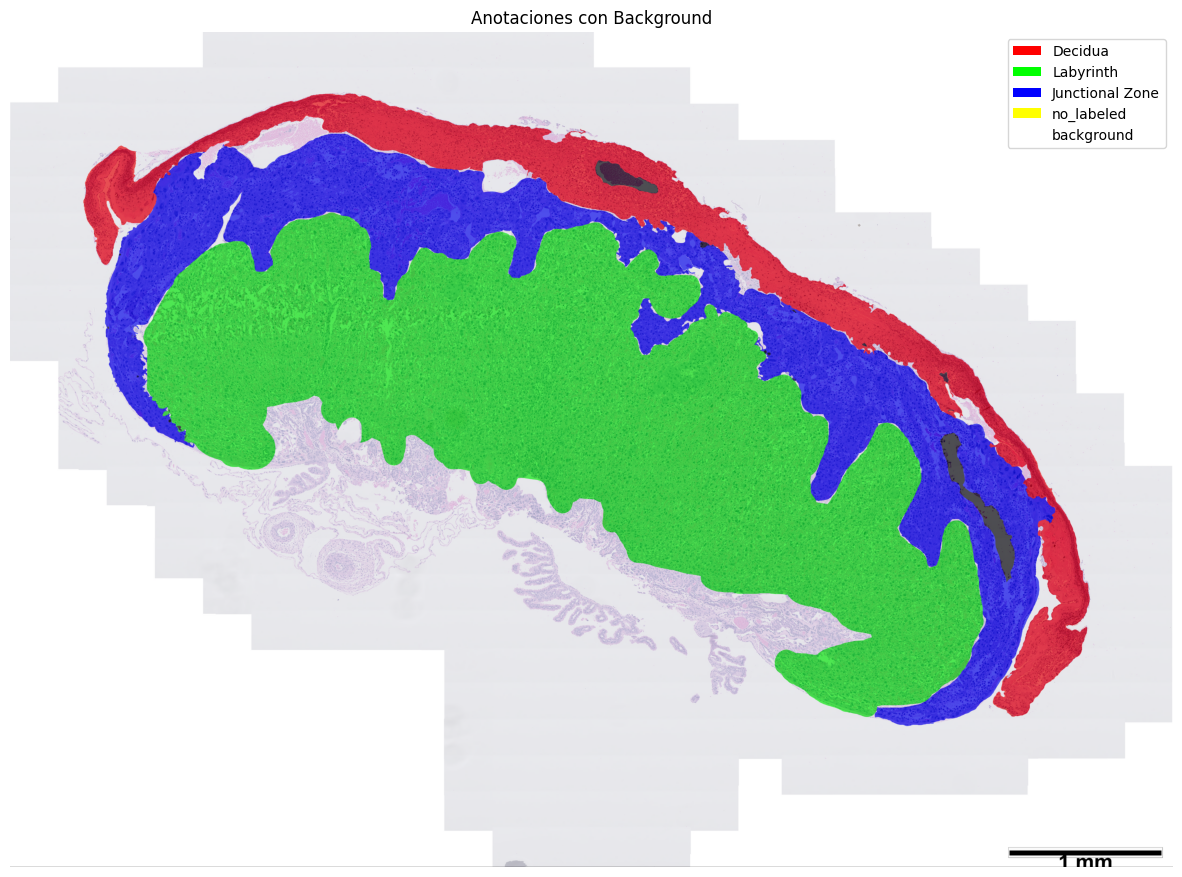

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]]

In [33]:
visualize_annotations_with_background(img_rgb, new_annotations)

In [31]:
# Debug: ver qué clases hay en las anotaciones
classes = {}
for f in new_annotations['features']:
    name = f['properties'].get('name', 'unknown')
    classes[name] = classes.get(name, 0) + 1

print("Clases encontradas:")
for name, count in classes.items():
    print(f"  {name}: {count} features")

Clases encontradas:
  Junctional Zone: 2 features
  Labyrinth: 2 features
  Decidua: 2 features
  background: 2 features


In [ ]:
output_geojson_path = OUTPUT_DIR / f"{slide_id}_with_background.geojson"

with open(output_geojson_path, 'w') as f:
    geojson.dump(new_annotations, f)

print(f"GeoJSON guardado en: {output_geojson_path}")

## 8. Batch Processing - Procesar Múltiples Slides

In [ ]:
def process_all_slides(wsi_dir, annot_dir, output_dir, 
                        sat_threshold=30, value_threshold=200, 
                        min_island_area=5000):
    """
    Procesa todos los slides con anotaciones disponibles.
    """
    # Obtener lista de archivos con anotaciones
    annot_files = sorted(annot_dir.glob("*.geojson"))
    
    results = []
    
    for annot_file in annot_files:
        slide_id = annot_file.stem
        wsi_file = wsi_dir / f"{slide_id}.tif"
        
        if not wsi_file.exists():
            print(f"⚠️  WSI no encontrado para {slide_id}, saltando...")
            continue
        
        print(f"Procesando {slide_id}...")
        
        try:
            result = clean_annotations(
                wsi_file, annot_file,
                sat_threshold, value_threshold,
                min_island_area,
                visualize=False
            )
            
            # Guardar
            output_path = output_dir / f"{slide_id}_cleaned.png"
            cv2.imwrite(str(output_path), result['cleaned_mask'])
            
            results.append({
                'slide_id': slide_id,
                'original_area': np.sum(result['original_mask'] > 0),
                'corrected_area': np.sum(result['cleaned_mask'] > 0),
                'removed_area': np.sum(result['removed_islands'] > 0)
            })
            
        except Exception as e:
            print(f"❌ Error procesando {slide_id}: {e}")
    
    return results

# Procesar todos los slides
all_results = process_all_slides(WSI_DIR, ANNOT_DIR, OUTPUT_DIR)

# Mostrar resumen
print("\n" + "="*60)
print("RESUMEN DE PROCESAMIENTO")
print("="*60)

total_original = sum(r['original_area'] for r in all_results)
total_corrected = sum(r['corrected_area'] for r in all_results)
total_removed = sum(r['removed_area'] for r in all_results)

print(f"Slides procesados: {len(all_results)}")
print(f"Área total original: {total_original:,} px")
print(f"Área total corregida: {total_corrected:,} px")
print(f"Área total eliminada: {total_removed:,} px ({total_removed/total_original*100:.2f}%)")